# Notebook 3: Exploratory Data Analysis (EDA)

This notebook explores the cleaned retail sales dataset to uncover trends, patterns, and business insights through descriptive statistics and visualizations.

In [4]:
#Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")# clean style for visualizations
pd.set_option('display.max_columns', None) # display all columns in the dataframe

print("Libraries imported successfully!")




Libraries imported successfully!


## Step 2: Load the Cleaned Dataset

Load the cleaned dataset prepared in Notebook 2 for exploratory data analysis.

In [6]:
df = pd.read_csv("../data/processed/Kenya_Retail_Sales_Cleaned.csv",
                  parse_dates=["Date"])
print("Data loaded successfully!")

Data loaded successfully!


## Step 3: Preview the Dataset

Display the first few records to verify that the dataset loaded correctly.

In [7]:
#Display the first 5 rows of the dataframe
df.head()

,Invoice_ID,Date,Time,Branch,City,Customer_ID,Customer_Type,Gender,Product_Category,Product,Quantity,Unit_Price,Discount,Tax,Total_Sales,Cost,Profit,Payment_Method,Rating,Cashier,Salesperson,Year,Month,Month Name,Quarter,Day,Day Name,Hour,Day Type
0,INV100000,2026-07-01,1900-01-01 16:41:00,Eldoret,Uasin Gishu,CUST3086,Member,Female,Electronics,Power Bank,10,814.98,0.15,1108.37,8035.70,4450.62,2476.71,Credit Card,6.5,Wanjiku,Grace,2026,7,July,3,1,Wednesday,16,Weekday
1,INV100001,2025-10-11,1900-01-01 15:11:00,Mombasa,Mombasa,CUST2099,Member,Male,Beverages,Tea,2,4257.21,0.00,1362.31,9876.73,5179.41,3335.01,Cash,5.5,Mutua,Mercy,2025,10,October,4,11,Saturday,15,Weekend
2,INV100002,2025-04-24,1900-01-01 13:01:00,Kisumu,Kisumu,CUST7763,Member,Male,Groceries,Cooking Oil,4,4723.78,0.00,3023.22,21918.34,11798.37,7096.75,Credit Card,7.0,Mutua,Brian,2025,4,April,2,24,Thursday,13,Weekday
3,INV100003,2026-02-13,1900-01-01 11:37:00,Kisumu,Kisumu,CUST1881,Normal,Female,Electronics,Power Bank,6,2821.15,0.00,2708.30,19635.20,9630.79,7296.11,M-Pesa,8.6,Wanjiku,John,2026,2,February,1,13,Friday,11,Weekday
4,INV100004,2026-08-30,1900-01-01 13:54:00,Nakuru,Nakuru,CUST8901,Normal,Male,Groceries,Milk,10,1891.46,0.15,2572.39,18649.80,12685.56,3391.85,Credit Card,6.7,Wanjiku,Brian,2026,8,August,3,30,Sunday,13,Weekend


## Step 4: Check Dataset Dimensions

View the number of rows and columns in the dataset.

In [8]:
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

Rows: 50000, Columns: 29


## Step 5: Display Column Names

List all columns available for analysis.

In [11]:

#displays all the columns
df.columns  

Index(['Invoice_ID', 'Date', 'Time', 'Branch', 'City', 'Customer_ID',
       'Customer_Type', 'Gender', 'Product_Category', 'Product', 'Quantity',
       'Unit_Price', 'Discount', 'Tax', 'Total_Sales', 'Cost', 'Profit',
       'Payment_Method', 'Rating', 'Cashier', 'Salesperson', 'Year', 'Month',
       'Month Name', 'Quarter', 'Day', 'Day Name', 'Hour', 'Day Type'],
      dtype='str')

## Total Revenue

Calculate the total revenue generated from all sales transactions.

In [15]:
#calculate total revenue
total_revenue = df['Total_Sales'].sum()
print(f"Total Revenue: KES {total_revenue:,.2f}")

Total Revenue: KES 741,046,306.09


## Total Profit

Calculate the total profit earned from all sales transactions.

In [16]:
total_profit = df['Profit'].sum()
print(f"Total Profit: KES {total_profit:,.2f}")

Total Profit: KES 191,360,934.10


## Total Transactions

Count the total number of sales transactions recorded in the dataset.

In [19]:
total_transactions =len(df)
print(f"Total Transactions: {total_transactions:,}")


Total Transactions: 50,000


## Average Transaction Value

Calculate the average amount spent per transaction.

In [ ]:
#calculates average revenue per transaction
average_transaction_value =df['Total_Sales'].mean()
print(f"Average Transaction Value: KES {average_transaction_value:,.2f}")

Average Transaction Value: KES 14,820.93


## Average Profit per Transaction

Calculate the average profit generated from each sales transaction.

In [21]:
# Calculate average profit per transaction
average_profit = df["Profit"].mean()

print(f"Average Profit per Transaction: KES {average_profit:,.2f}")

Average Profit per Transaction: KES 3,827.22


## Business KPI Summary

Display the key performance indicators in one place for a quick overview of business performance.

In [22]:
#Display Business KPIs
print("=" * 40)
print("Business KPIs SUMMARY")
print("=" * 40)
print(f"Total Revenue: KES {total_revenue:,.2f}")
print(f"Total Profit: KES {total_profit:,.2f}")
print(f"Total Transactions: {total_transactions:,}")
print(f"Average Transaction Value: KES {average_transaction_value:,.2f}")
print(f"Average Profit per Transaction: KES {average_profit:,.2f}")

Business KPIs SUMMARY
Total Revenue: KES 741,046,306.09
Total Profit: KES 191,360,934.10
Total Transactions: 50,000
Average Transaction Value: KES 14,820.93
Average Profit per Transaction: KES 3,827.22


## Revenue by Branch

Analyze the total revenue generated by each branch.

In [23]:
# Calculate total revenue by branch
branch_revenue = (
    df.groupby("Branch")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

branch_revenue

Branch
Nakuru         1.069901e+08
Mombasa        1.069765e+08
Eldoret        1.064426e+08
Westlands      1.057603e+08
Migori         1.051070e+08
Kisumu         1.050057e+08
Nairobi CBD    1.047641e+08
Name: Total_Sales, dtype: float64

## Revenue by Branch Chart

Visualize the total revenue generated by each branch.

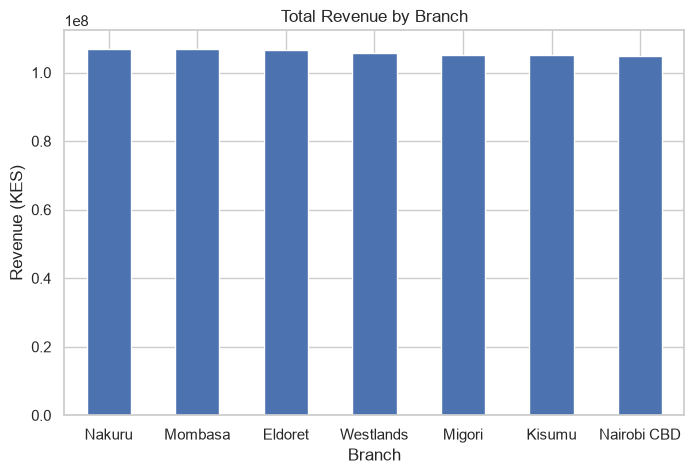

In [24]:
# Plot revenue by branch
plt.figure(figsize=(8,5))

branch_revenue.plot(kind="bar")

plt.title("Total Revenue by Branch")
plt.xlabel("Branch")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=0)

plt.show()

## Profit by Branch

Analyze the total profit earned by each branch.

In [25]:
# Calculate total profit by branch
branch_profit = (
    df.groupby("Branch")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

branch_profit

Branch
Eldoret        27584451.30
Mombasa        27537270.80
Nakuru         27530326.44
Migori         27311467.44
Westlands      27290291.29
Kisumu         27265106.86
Nairobi CBD    26842019.97
Name: Profit, dtype: float64

## Revenue by City

Analyze the total revenue generated by each city.

In [26]:
# Calculate total revenue by city
city_revenue = (
    df.groupby("City")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

city_revenue

City
Nairobi        2.105244e+08
Nakuru         1.069901e+08
Mombasa        1.069765e+08
Uasin Gishu    1.064426e+08
Migori         1.051070e+08
Kisumu         1.050057e+08
Name: Total_Sales, dtype: float64

## Profit by City

Analyze the total profit earned by each city.

In [27]:
# Calculate total profit by city
city_profit = (
    df.groupby("City")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

city_profit

City
Nairobi        54132311.26
Uasin Gishu    27584451.30
Mombasa        27537270.80
Nakuru         27530326.44
Migori         27311467.44
Kisumu         27265106.86
Name: Profit, dtype: float64

## Revenue by City Chart

Visualize the total revenue generated by each city.

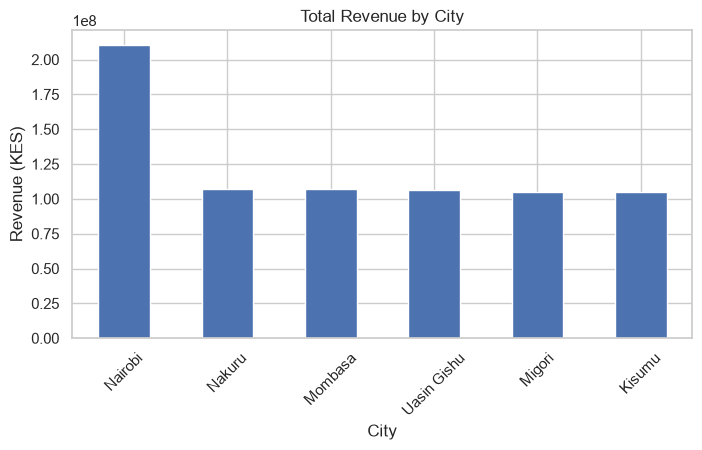

In [32]:
# Plot revenue by city
plt.figure(figsize=(8,4))

city_revenue.plot(kind="bar")

plt.title("Total Revenue by City")
plt.xlabel("City")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=45)

plt.show()

## Revenue by Product Category

Analyze the total revenue generated by each product category.

In [33]:
# Calculate total revenue by product category
category_revenue = (
    df.groupby("Product_Category")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

category_revenue

Product_Category
Household      1.498403e+08
Beverages      1.494720e+08
Electronics    1.489817e+08
Stationery     1.467696e+08
Groceries      1.459827e+08
Name: Total_Sales, dtype: float64

## Revenue by Product Category Chart

Visualize the revenue generated by each product category.

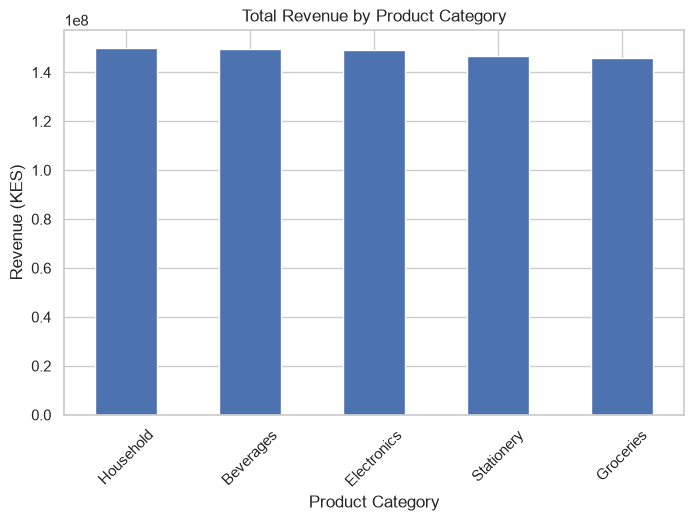

In [35]:
# Plot revenue by product category
plt.figure(figsize=(8,5))

category_revenue.plot(kind="bar")

plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=45)

plt.show()

## Profit by Product Category

Analyze the total profit earned by each product category.

In [36]:
# Calculate total profit by product category
category_profit = (
    df.groupby("Product_Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

category_profit

Product_Category
Electronics    38594506.08
Beverages      38492597.87
Household      38468709.21
Stationery     37931377.66
Groceries      37873743.28
Name: Profit, dtype: float64

## Top 10 Products by Revenue

Identify the products that generate the highest revenue.

In [37]:
# Top 10 products by revenue
top_products_revenue = (
    df.groupby("Product")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products_revenue

Product
Bucket        30678061.78
Detergent     30487143.99
Coffee        30478338.93
Power Bank    30415971.23
Soda          30404172.09
Juice         30365284.72
USB Flash     30311331.53
Book          29890530.14
Rice          29830726.37
Headphones    29713346.04
Name: Total_Sales, dtype: float64

## Top 10 Products by Revenue Chart

Visualize the products generating the highest revenue.

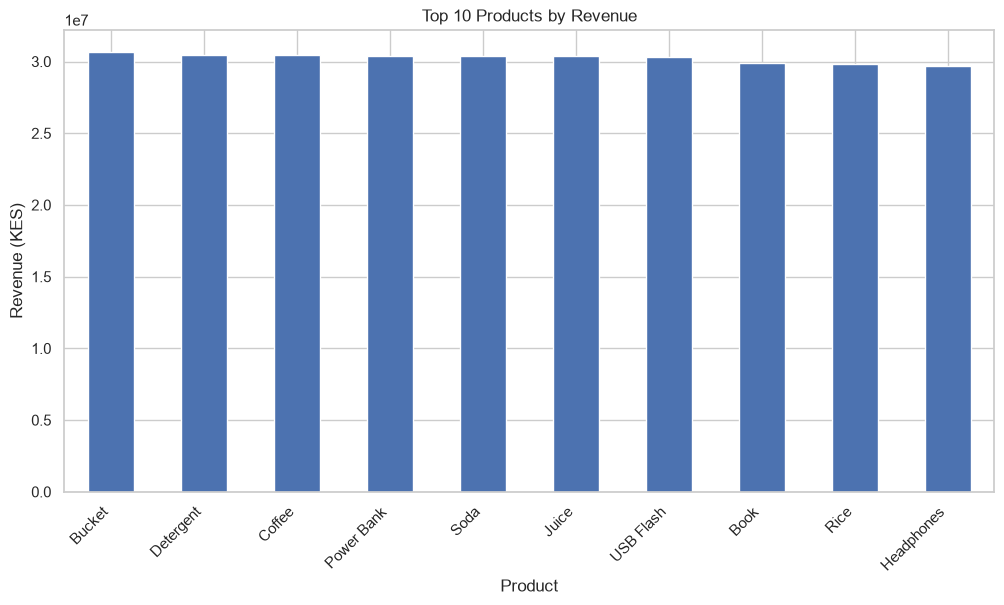

In [38]:
# Plot top 10 products by revenue
plt.figure(figsize=(12,6))

top_products_revenue.plot(kind="bar")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Product")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=45, ha="right")

plt.show()

## Top 10 Products by Profit

Identify the products generating the highest profit.

In [39]:
# Top 10 products by profit
top_products_profit = (
    df.groupby("Product")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products_profit

Product
USB Flash     7894317.08
Book          7883422.08
Bucket        7843213.27
Power Bank    7832803.20
Juice         7825329.53
Headphones    7810372.63
Detergent     7789491.97
Coffee        7783734.41
Soda          7770028.94
Rice          7748124.80
Name: Profit, dtype: float64

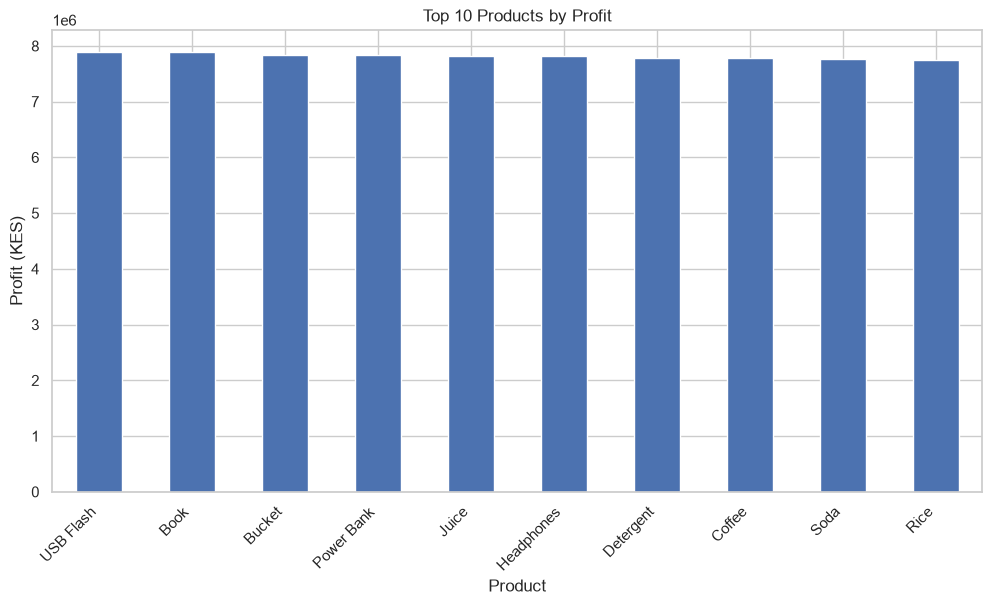

In [40]:
# Plot top 10 products by profit
plt.figure(figsize=(12,6))

top_products_profit.plot(kind="bar")

plt.title("Top 10 Products by Profit")
plt.xlabel("Product")
plt.ylabel("Profit (KES)")
plt.xticks(rotation=45, ha="right")

plt.show()

In [42]:
# Plot revenue by customer type
# Calculate total revenue by customer type
customer_revenue = (
    df.groupby("Customer_Type")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

customer_revenue

Customer_Type
Member    3.727715e+08
Normal    3.682748e+08
Name: Total_Sales, dtype: float64

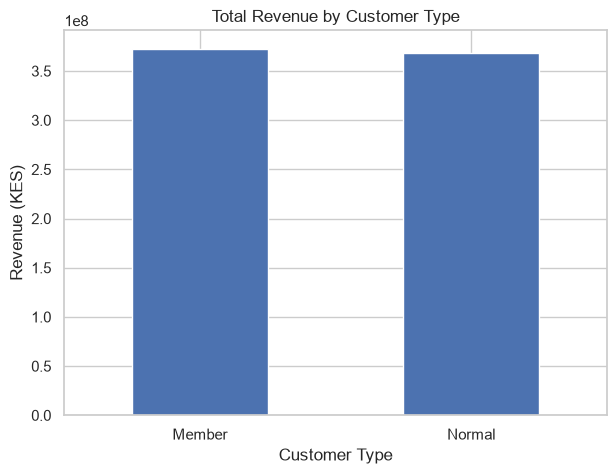

In [43]:
# Plot revenue by customer type
plt.figure(figsize=(7,5))

customer_revenue.plot(kind="bar")

plt.title("Total Revenue by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=0)

plt.show()

In [44]:
# Count transactions by customer type
customer_transactions = (
    df["Customer_Type"]
    .value_counts()
)

customer_transactions

Customer_Type
Member    25137
Normal    24863
Name: count, dtype: int64

In [45]:
# Calculate total revenue by gender
gender_revenue = (
    df.groupby("Gender")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

gender_revenue

Gender
Female    3.710746e+08
Male      3.699717e+08
Name: Total_Sales, dtype: float64

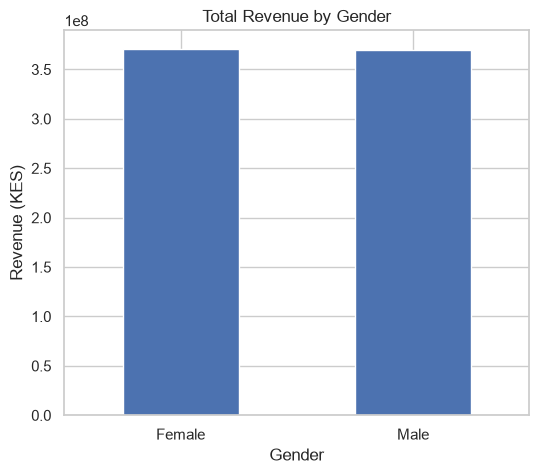

In [46]:
# Plot revenue by gender
plt.figure(figsize=(6,5))

gender_revenue.plot(kind="bar")

plt.title("Total Revenue by Gender")
plt.xlabel("Gender")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=0)

plt.show()

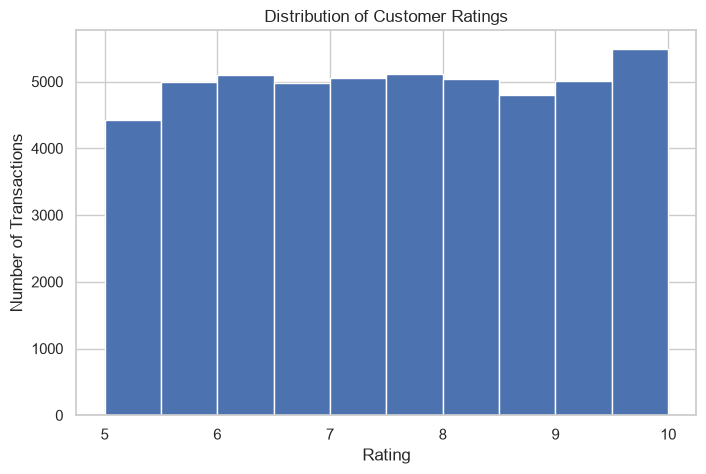

In [47]:
# Plot customer rating distribution
plt.figure(figsize=(8,5))

plt.hist(df["Rating"], bins=10)

plt.title("Distribution of Customer Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Transactions")

plt.show()

In [48]:
# Calculate average rating by customer type
average_rating = (
    df.groupby("Customer_Type")["Rating"]
    .mean()
    .sort_values(ascending=False)
)

average_rating

Customer_Type
Member    7.501396
Normal    7.497840
Name: Rating, dtype: float64

## Transactions by Payment Method

Count the number of transactions completed using each payment method.

In [49]:
# Count transactions by payment method
payment_transactions = (
    df["Payment_Method"]
    .value_counts()
)

payment_transactions

Payment_Method
Credit Card    12579
Cash           12562
M-Pesa         12494
Debit Card     12365
Name: count, dtype: int64

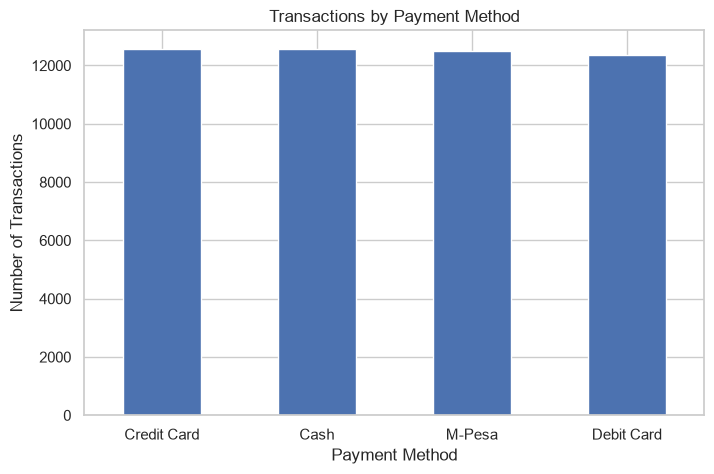

In [50]:
# Plot transactions by payment method
plt.figure(figsize=(8,5))

payment_transactions.plot(kind="bar")

plt.title("Transactions by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)

plt.show()

In [51]:
# Calculate revenue by payment method
payment_revenue = (
    df.groupby("Payment_Method")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

payment_revenue

Payment_Method
Cash           1.872907e+08
Credit Card    1.865366e+08
M-Pesa         1.850064e+08
Debit Card     1.822126e+08
Name: Total_Sales, dtype: float64

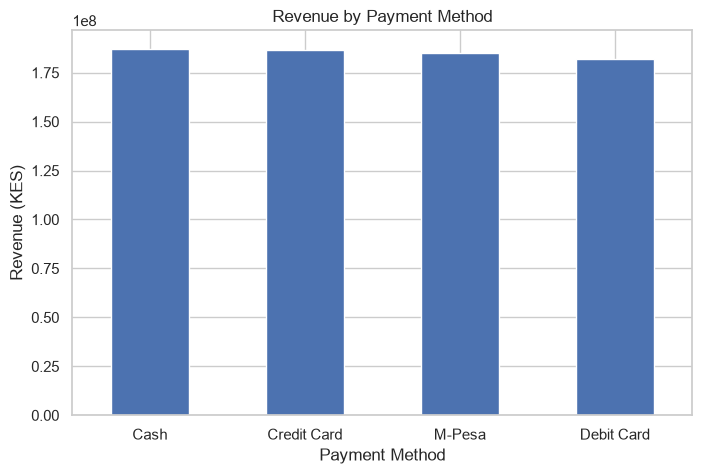

In [52]:
# Plot revenue by payment method
plt.figure(figsize=(8,5))

payment_revenue.plot(kind="bar")

plt.title("Revenue by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=0)

plt.show()

In [53]:
# Calculate profit by payment method
payment_profit = (
    df.groupby("Payment_Method")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

payment_profit

Payment_Method
Cash           48405339.19
Credit Card    48278238.52
M-Pesa         47611320.30
Debit Card     47066036.09
Name: Profit, dtype: float64

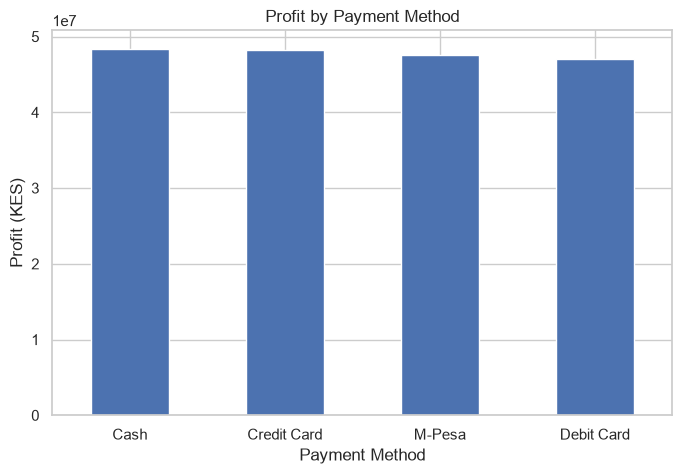

In [54]:
# Plot profit by payment method
plt.figure(figsize=(8,5))

payment_profit.plot(kind="bar")

plt.title("Profit by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Profit (KES)")
plt.xticks(rotation=0)

plt.show()

In [55]:
# Calculate revenue by salesperson
salesperson_revenue = (
    df.groupby("Salesperson")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

salesperson_revenue

Salesperson
Brian    1.253229e+08
John     1.248499e+08
Grace    1.247396e+08
Mercy    1.227443e+08
Faith    1.225242e+08
Kevin    1.208654e+08
Name: Total_Sales, dtype: float64

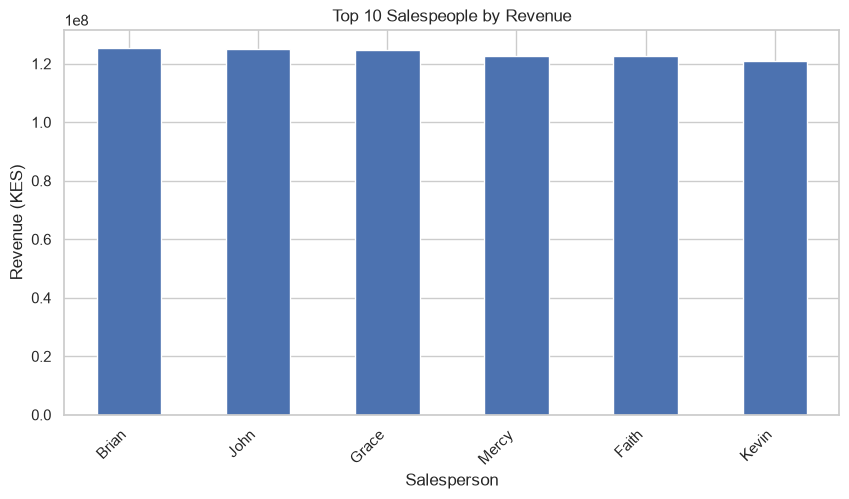

In [56]:
# Plot top salespeople by revenue
plt.figure(figsize=(10,5))

salesperson_revenue.plot(kind="bar")

plt.title("Top 10 Salespeople by Revenue")
plt.xlabel("Salesperson")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=45, ha="right")

plt.show()

In [57]:
# Calculate profit by salesperson
salesperson_profit = (
    df.groupby("Salesperson")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

salesperson_profit

Salesperson
Grace    32266232.79
Brian    32232954.52
John     32083434.37
Mercy    31927399.57
Faith    31484092.26
Kevin    31366820.59
Name: Profit, dtype: float64

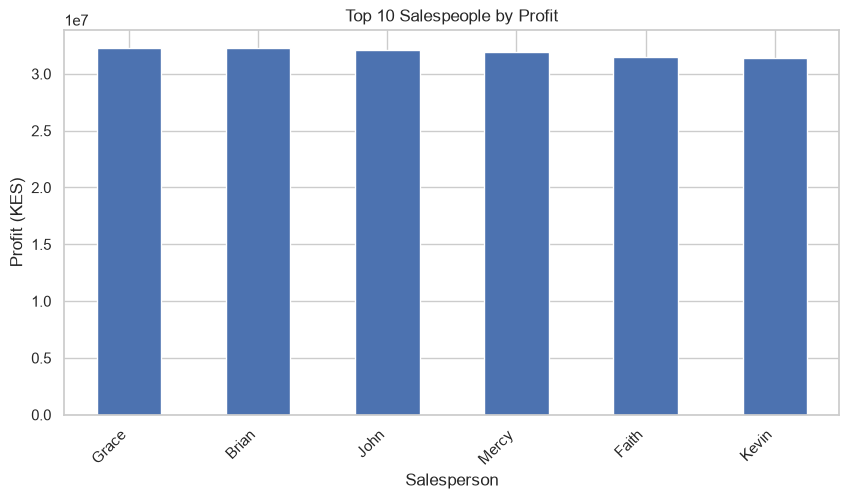

In [58]:
# Plot top salespeople by profit
plt.figure(figsize=(10,5))

salesperson_profit.plot(kind="bar")

plt.title("Top 10 Salespeople by Profit")
plt.xlabel("Salesperson")
plt.ylabel("Profit (KES)")
plt.xticks(rotation=45, ha="right")

plt.show()

In [59]:
# Count transactions by cashier
cashier_transactions = (
    df["Cashier"]
    .value_counts()
    .head(10)
)

cashier_transactions

Cashier
Wanjiku    8425
Kamau      8369
Omondi     8311
Achieng    8307
Mutua      8295
Otieno     8293
Name: count, dtype: int64

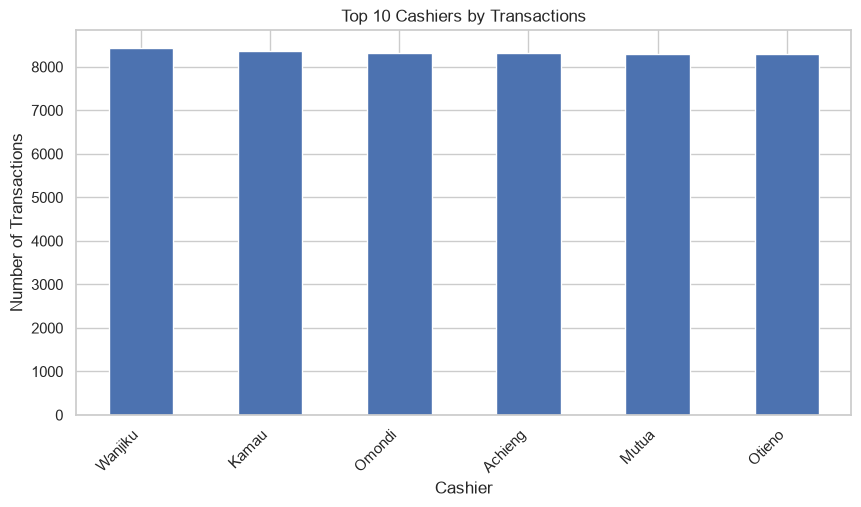

In [60]:
# Plot top cashiers by transactions
plt.figure(figsize=(10,5))

cashier_transactions.plot(kind="bar")

plt.title("Top 10 Cashiers by Transactions")
plt.xlabel("Cashier")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45, ha="right")

plt.show()

In [61]:
# Calculate revenue by year
sales_by_year = (
    df.groupby("Year")["Total_Sales"]
    .sum()
)

sales_by_year

Year
2025    3.665450e+08
2026    3.745013e+08
Name: Total_Sales, dtype: float64

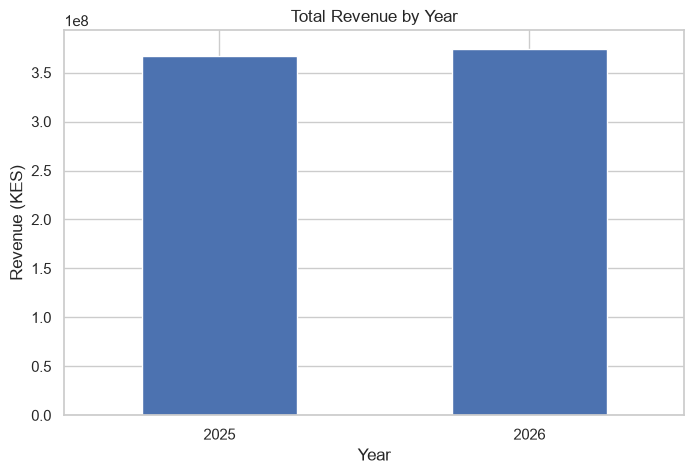

In [62]:
# Plot sales by year
plt.figure(figsize=(8,5))

sales_by_year.plot(kind="bar")

plt.title("Total Revenue by Year")
plt.xlabel("Year")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=0)

plt.show()

In [63]:
# Calculate revenue by quarter
sales_by_quarter = (
    df.groupby("Quarter")["Total_Sales"]
    .sum()
    .sort_index()
)

sales_by_quarter

Quarter
1    1.812080e+08
2    1.840560e+08
3    1.877375e+08
4    1.880448e+08
Name: Total_Sales, dtype: float64

In [64]:
# Calculate revenue by month
sales_by_month = (
    df.groupby("Month Name")["Total_Sales"]
    .sum()
    .reindex([
        "January", "February", "March", "April",
        "May", "June", "July", "August",
        "September", "October", "November", "December"
    ])
)

sales_by_month

Month Name
January      60215577.95
February     58143682.29
March        62848738.46
April        58267628.04
May          64557363.87
June         61230996.33
July         62411543.69
August       64049681.11
September    61276304.37
October      63723966.30
November     59486871.25
December     64833952.43
Name: Total_Sales, dtype: float64

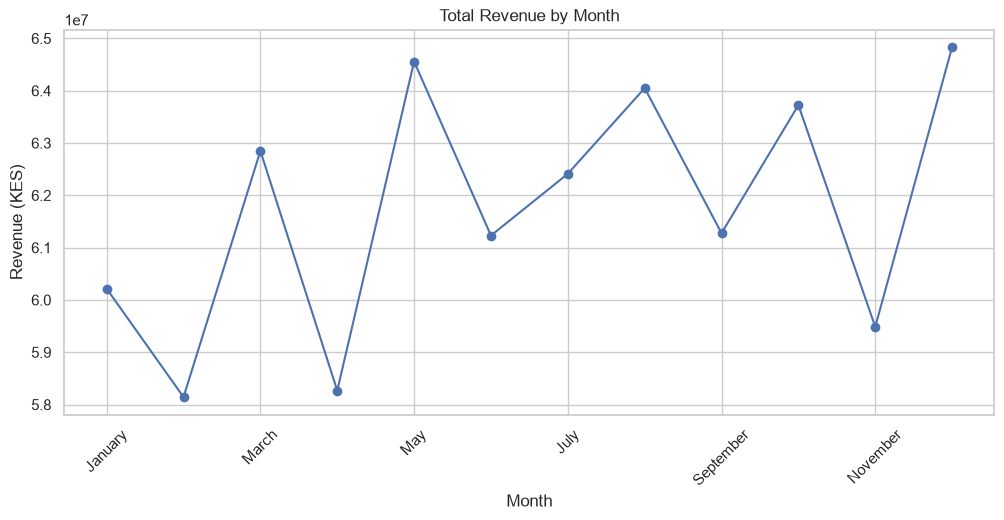

In [65]:
# Plot sales by month
plt.figure(figsize=(12,5))

sales_by_month.plot(kind="line", marker="o")

plt.title("Total Revenue by Month")
plt.xlabel("Month")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=45)

plt.show()

In [66]:
# Calculate revenue by day type
day_type_sales = (
    df.groupby("Day Type")["Total_Sales"]
    .sum()
)

day_type_sales

Day Type
Weekday    5.322555e+08
Weekend    2.087908e+08
Name: Total_Sales, dtype: float64

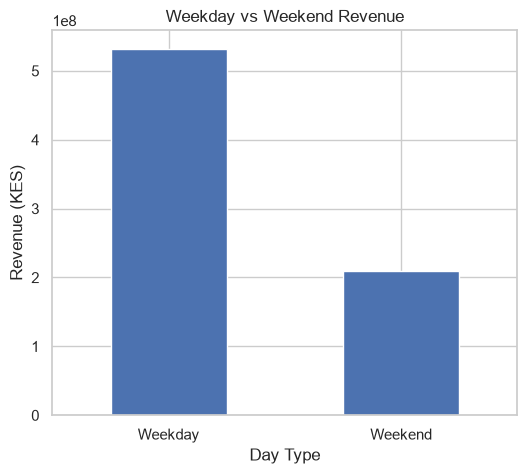

In [67]:
# Plot weekday vs weekend sales
plt.figure(figsize=(6,5))

day_type_sales.plot(kind="bar")

plt.title("Weekday vs Weekend Revenue")
plt.xlabel("Day Type")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=0)

plt.show()

In [68]:
# Calculate revenue by hour
sales_by_hour = (
    df.groupby("Hour")["Total_Sales"]
    .sum()
    .sort_index()
)

sales_by_hour

Hour
8     55839055.02
9     56599429.31
10    58404152.27
11    56821122.97
12    57451422.07
13    54749643.17
14    58305903.89
15    58227822.77
16    56267583.68
17    58059802.10
18    56553424.60
19    57036239.03
20    56730705.21
Name: Total_Sales, dtype: float64

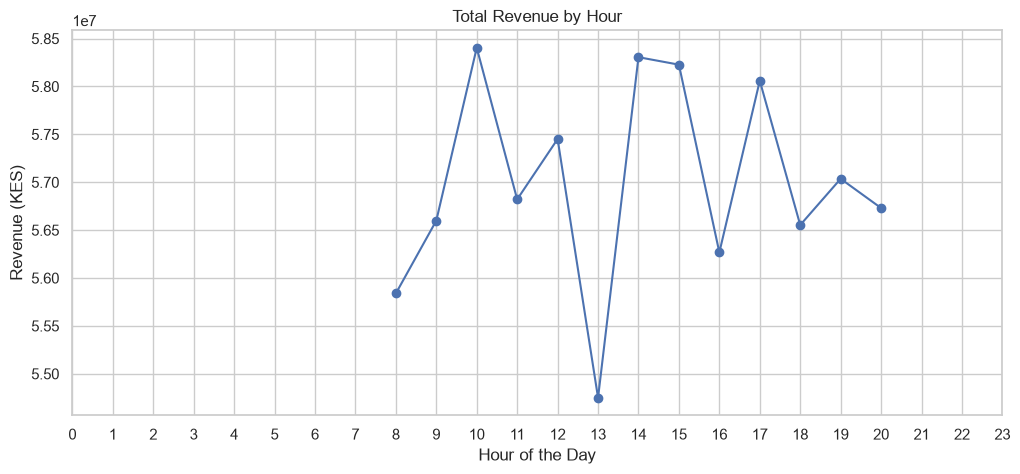

In [69]:
# Plot sales by hour
plt.figure(figsize=(12,5))

sales_by_hour.plot(kind="line", marker="o")

plt.title("Total Revenue by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Revenue (KES)")
plt.xticks(range(24))

plt.show()

## Summary Statistics

Display descriptive statistics for the numerical variables in the dataset.

In [70]:
# Display summary statistics
df.describe()

,Date,Quantity,Unit_Price,Discount,Tax,Total_Sales,Cost,Profit,Rating,Year,Month,Quarter,Day,Hour
count,50000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000
mean,2026-01-01 13:14:51.072000,5.490480,2518.300978,0.075087,2044.265679,14820.926122,8949.441761,3827.218682,7.499628,2025.502000,6.536320,2.51108,15.730320,14.028300
min,2025-01-01 00:00:00,1.000000,50.230000,0.000000,6.930000,50.250000,26.900000,10.670000,5.000000,2025.000000,1.000000,1.00000,1.000000,8.000000
25%,2025-07-04 00:00:00,3.000000,1280.072500,0.050000,645.985000,4683.370000,2788.077500,1134.430000,6.200000,2025.000000,4.000000,2.00000,8.000000,11.000000
50%,2026-01-02 00:00:00,5.000000,2510.855000,0.100000,1560.960000,11316.940000,6774.085000,2781.210000,7.500000,2026.000000,7.000000,3.00000,16.000000,14.000000
75%,2026-07-02 00:00:00,8.000000,3758.467500,0.150000,3064.285000,22216.055000,13316.382500,5526.727500,8.700000,2026.000000,10.000000,4.00000,23.000000,17.000000
max,2026-12-31 00:00:00,10.000000,4999.840000,0.150000,7997.440000,57981.440000,41721.180000,21334.100000,10.000000,2026.000000,12.000000,4.00000,31.000000,20.000000
std,NaN,2.871027,1430.062939,0.055941,1696.553888,12300.015713,7571.809611,3482.066138,1.440407,0.500001,3.442905,1.11516,8.776959,3.741649


In [71]:
# Calculate the correlation matrix
correlation = df.corr(numeric_only=True)

correlation

,Quantity,Unit_Price,Discount,Tax,Total_Sales,Cost,Profit,Rating,Year,Month,Quarter,Day,Hour
Quantity,1.000000,-0.003225,-0.005303,0.628808,0.628808,0.617519,0.572019,0.001630,0.008679,0.002295,0.001364,0.001485,-0.002716
Unit_Price,-0.003225,1.000000,0.001885,0.682080,0.682080,0.669236,0.621781,-0.005547,0.002965,0.002252,0.000757,0.001239,-0.003153
Discount,-0.005303,0.001885,1.000000,-0.073372,-0.073372,-0.071140,-0.068736,0.003286,-0.003206,-0.001462,-0.000697,-0.003563,-0.003201
Tax,0.628808,0.682080,-0.073372,1.000000,1.000000,0.981729,0.910378,-0.005856,0.008118,0.007058,0.005665,0.000860,-0.006959
Total_Sales,0.628808,0.682080,-0.073372,1.000000,1.000000,0.981729,0.910378,-0.005856,0.008118,0.007058,0.005665,0.000860,-0.006959
Cost,0.617519,0.669236,-0.071140,0.981729,0.981729,1.000000,0.815009,-0.006660,0.009295,0.004574,0.003394,0.000382,-0.006373
Profit,0.572019,0.621781,-0.068736,0.910378,0.910378,0.815009,1.000000,-0.003350,0.004506,0.011546,0.009872,0.001789,-0.007335
Rating,0.001630,-0.005547,0.003286,-0.005856,-0.005856,-0.006660,-0.003350,1.000000,0.001112,0.003851,0.004535,0.000994,-0.002658
Year,0.008679,0.002965,-0.003206,0.008118,0.008118,0.009295,0.004506,0.001112,1.000000,-0.003179,-0.003160,-0.002721,0.007052
Month,0.002295,0.002252,-0.001462,0.007058,0.007058,0.004574,0.011546,0.003851,-0.003179,1.000000,0.971350,0.009173,0.001025


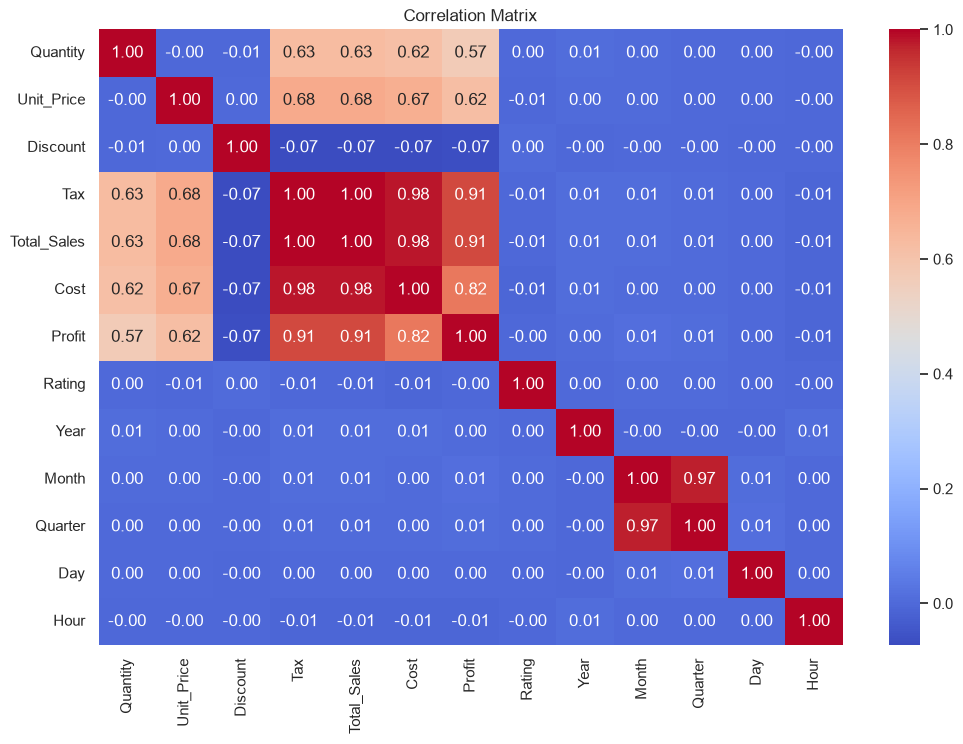

In [72]:
# Plot the correlation heatmap
plt.figure(figsize=(12,8))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Matrix")

plt.show()

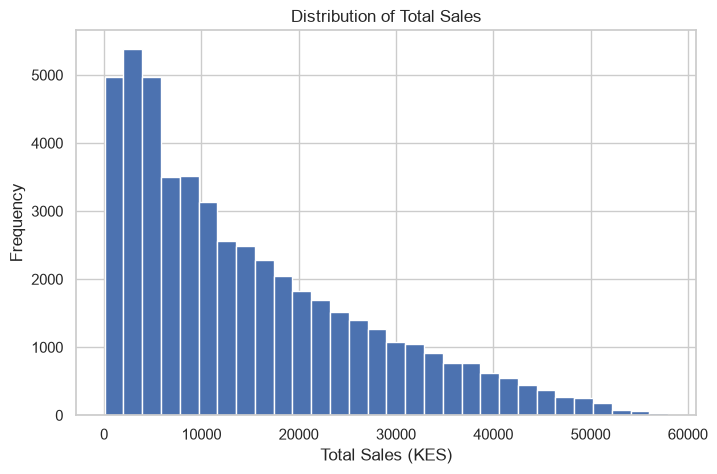

In [73]:
# Plot distribution of total sales
plt.figure(figsize=(8,5))

plt.hist(df["Total_Sales"], bins=30)

plt.title("Distribution of Total Sales")
plt.xlabel("Total Sales (KES)")
plt.ylabel("Frequency")

plt.show()

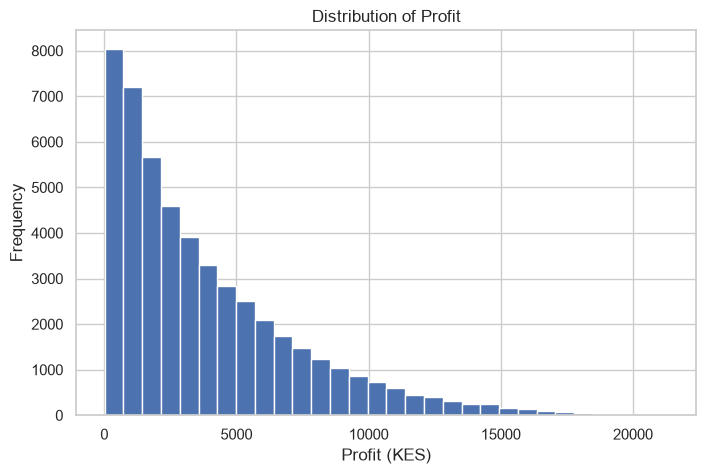

In [74]:
# Plot distribution of profit
plt.figure(figsize=(8,5))

plt.hist(df["Profit"], bins=30)

plt.title("Distribution of Profit")
plt.xlabel("Profit (KES)")
plt.ylabel("Frequency")

plt.show()

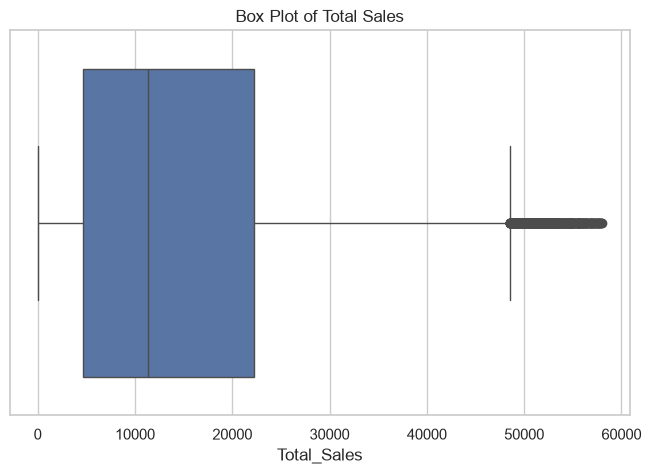

In [75]:
# Plot box plot for total sales
plt.figure(figsize=(8,5))

sns.boxplot(x=df["Total_Sales"])

plt.title("Box Plot of Total Sales")

plt.show()

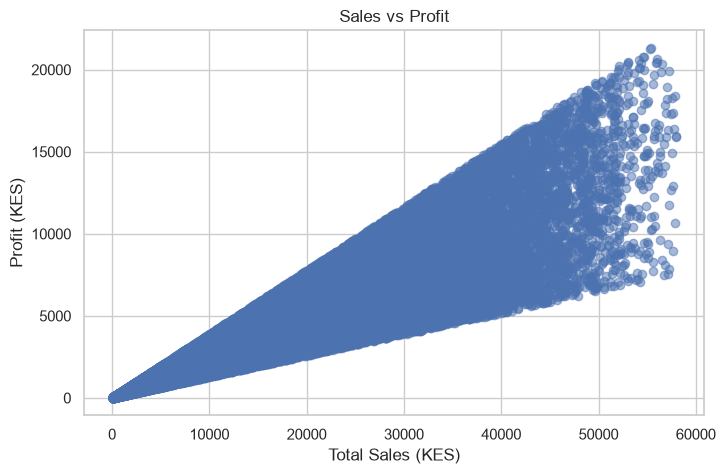

In [76]:
# Scatter plot of sales and profit
plt.figure(figsize=(8,5))

plt.scatter(df["Total_Sales"], df["Profit"], alpha=0.5)

plt.title("Sales vs Profit")
plt.xlabel("Total Sales (KES)")
plt.ylabel("Profit (KES)")

plt.show()

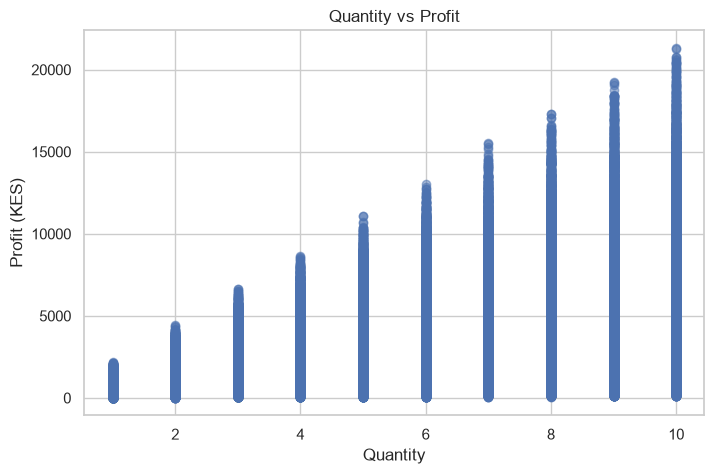

In [77]:
# Scatter plot of quantity and profit
plt.figure(figsize=(8,5))

plt.scatter(df["Quantity"], df["Profit"], alpha=0.5)

plt.title("Quantity vs Profit")
plt.xlabel("Quantity")
plt.ylabel("Profit (KES)")

plt.show()

# Section 10: Key Business Insights

Summarize the main findings from the exploratory data analysis and highlight the key trends that can support business decision-making.

## Business Insights

The exploratory data analysis revealed several important insights about the business:

- The business generated **KES 741.05 million** in total revenue and **KES 191.36 million** in total profit from **50,000 transactions**.
- The average customer spent **KES 14,820.93** per transaction, generating an average profit of **KES 3,827.22**.
- **Nakuru** was the highest revenue-generating branch, while **Nairobi** was the most profitable city.
- The **Household** category generated the highest revenue, with **Bucket** emerging as the top-selling product.
- **Credit Card** was the most preferred payment method, indicating strong adoption of cashless payments.
- **Members** contributed the highest revenue, suggesting that loyalty programs positively influence customer spending.
- **Brian** was the highest-performing salesperson, while **Wanjiku** processed the most transactions among cashiers.
- **December** recorded the highest sales, indicating strong seasonal demand during the holiday period.

These insights provide a clear understanding of the company's performance and form the foundation for answering business questions and making strategic recommendations in the next notebook.

In [81]:
# Calculate KPIs
total_revenue = df["Total_Sales"].sum()
total_profit = df["Profit"].sum()
total_transactions = len(df)
average_transaction = df["Total_Sales"].mean()
average_profit = df["Profit"].mean()

print("=" * 60)
print("KEY BUSINESS INSIGHTS")
print("=" * 60)

print(f"• Total Revenue: KES {total_revenue:,.2f}")
print(f"• Total Profit: KES {total_profit:,.2f}")
print(f"• Total Transactions: {total_transactions:,}")
print(f"• Average Transaction Value: KES {average_transaction:,.2f}")
print(f"• Average Profit per Transaction: KES {average_profit:,.2f}")

print(f"\nHighest Revenue Branch: {branch_revenue.idxmax()}")
print(f"Most Profitable City: {city_profit.idxmax()}")
print(f"Top Product Category: {category_revenue.idxmax()}")
print(f"Top Selling Product: {top_products_revenue.idxmax()}")
print(f"Most Preferred Payment Method: {payment_transactions.idxmax()}")
print(f"Top Customer Type: {customer_revenue.idxmax()}")
print(f"Top Salesperson: {salesperson_revenue.idxmax()}")
print(f"Busiest Cashier: {cashier_transactions.idxmax()}")
print(f"Highest Sales Month: {sales_by_month.idxmax()}")
print(f"Peak Shopping Hour: {sales_by_hour.idxmax()}")

KEY BUSINESS INSIGHTS
• Total Revenue: KES 741,046,306.09
• Total Profit: KES 191,360,934.10
• Total Transactions: 50,000
• Average Transaction Value: KES 14,820.93
• Average Profit per Transaction: KES 3,827.22

Highest Revenue Branch: Nakuru
Most Profitable City: Nairobi
Top Product Category: Household
Top Selling Product: Bucket
Most Preferred Payment Method: Credit Card
Top Customer Type: Member
Top Salesperson: Brian
Busiest Cashier: Wanjiku
Highest Sales Month: December
Peak Shopping Hour: 10
